# 02 — Tiền xử lý, biến đổi & nhật ký quyết định (Thành viên B – Cường)
**Đề tài 6 — Ngân hàng: Phát hiện giao dịch thẻ gian lận** · Họ bài toán chính: Phát hiện bất thường

**Đầu vào (từ Khang):** `data/raw/creditcard.csv` (sha256 `76274b69…98551a89`), `outputs/audit_metrics.json`, `outputs/quality_issues.csv`, `outputs/data_dictionary.csv`.

**Đầu ra (cho Quỳnh, Huy, Mong):**
- `data/processed/transactions_processed.csv` — đủ 284 807 dòng, schema cố định (`src/preprocessing.py::PROCESSED_COLS`), có cột chia tập.
- `outputs/decision_log.csv`, `outputs/processed_data_dictionary.md`, `outputs/processed_schema.json`, `outputs/preprocessing_checks.json`, `figures/fig04_amount_transform.png`.

**Quy tắc của notebook này**
- Chỉ ĐỌC file raw; cuối notebook kiểm tra lại checksum.
- Không xoá dòng nào khỏi file đã xử lý: bản sao được **gắn cờ**, không xoá.
- File đã xử lý chỉ chứa biến đổi **không học từ dữ liệu** (log1p, chia giờ, dải tiền). Biến đổi có học (StandardScaler) nằm trong `make_preprocessor()` và chỉ được fit trên train/fold.
- Logic nằm trong `src/preprocessing.py` để Huy/Mong import đúng một phiên bản; notebook này chạy, kiểm tra và ghi bằng chứng.
- Chạy từ `notebooks/`: Kernel → Restart & Run All.

In [1]:
from pathlib import Path
import sys, json, datetime, platform, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
import preprocessing as P

RAW_PATH  = ROOT / "data" / "raw" / "creditcard.csv"
PROC_DIR  = ROOT / "data" / "processed"; PROC_DIR.mkdir(parents=True, exist_ok=True)
PROC_PATH = PROC_DIR / "transactions_processed.csv"
OUT, FIG  = ROOT / "outputs", ROOT / "figures"
AUDIT     = json.loads((OUT / "audit_metrics.json").read_text(encoding="utf-8"))

C = {"schema_version": P.SCHEMA_VERSION, "run_date": datetime.date.today().isoformat(),
     "python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "sklearn": sklearn.__version__}
print(C)

{'schema_version': '1.0', 'run_date': '2026-10-30', 'python': '3.13.16', 'pandas': '3.0.2', 'numpy': '2.5.4', 'sklearn': '1.8.0'}


## 1. Nạp raw & đối chiếu với audit của Khang (bước B1, B4)
`load_raw()` dừng ngay nếu sha256, tên cột hoặc shape khác bản Khang đã audit.

In [2]:
raw = P.load_raw(RAW_PATH, verify=True)
C["raw_sha256_before"] = P.EXPECTED_SHA256
print("shape:", raw.shape)
print(raw.dtypes.value_counts().to_string())

shape: (284807, 31)
float64    30
int64       1


In [3]:
# Báo cáo TRƯỚC xử lý, tính lại độc lập rồi so với audit_metrics.json của Khang
pre = {
    "n_rows": len(raw), "n_cols": raw.shape[1],
    "n_fraud": int(raw["Class"].sum()), "n_nonfraud": int((raw["Class"] == 0).sum()),
    "n_missing_total": int(raw.isna().sum().sum()),
    "dup_extra_rows": int(raw.duplicated().sum()),
    "dup_extra_fraud": int(raw.loc[raw.duplicated(), "Class"].sum()),
    "amount_zero_rows": int((raw["Amount"] == 0).sum()),
    "amount_zero_fraud": int(raw.loc[raw["Amount"] == 0, "Class"].sum()),
    "amount_negative": int((raw["Amount"] < 0).sum()),
    "amount_max": float(raw["Amount"].max()),
    "time_min": float(raw["Time"].min()), "time_max": float(raw["Time"].max()),
    "time_non_integer": int((raw["Time"] != raw["Time"].round()).sum()),
}
cmp = pd.DataFrame({"tinh_lai": pre, "audit_Khang": {k: AUDIT[k] for k in pre}})
cmp["khop"] = cmp["tinh_lai"] == cmp["audit_Khang"]
C["pre_report"] = pre
C["pre_report_matches_audit"] = bool(cmp["khop"].all())
assert cmp["khop"].all(), "Số liệu khác audit của Khang, phải giải thích trước khi tiếp tục"
cmp

,tinh_lai,audit_Khang,khop
n_rows,284807.00,284807.00,True
n_cols,31.00,31.00,True
n_fraud,492.00,492.00,True
n_nonfraud,284315.00,284315.00,True
n_missing_total,0.00,0.00,True
dup_extra_rows,1081.00,1081.00,True
dup_extra_fraud,19.00,19.00,True
amount_zero_rows,1825.00,1825.00,True
amount_zero_fraud,27.00,27.00,True
amount_negative,0.00,0.00,True


## 2. Bằng chứng cho các quyết định xử lý (bước B5)
### 2.1 Bản sao hoàn toàn (DQ-01)
Câu hỏi cần trả lời: bản sao nằm ở đâu, có ảnh hưởng tới đánh giá không, và nếu loại thì mất bao nhiêu fraud?

In [4]:
dup_extra = raw.duplicated(keep="first")
grp_size = raw[raw.duplicated(keep=False)].groupby(list(raw.columns)).size()
print(f"bản sao thừa: {dup_extra.sum():,} (fraud {raw.loc[dup_extra,'Class'].sum()}) | số nhóm trùng: {len(grp_size)} | cỡ nhóm lớn nhất: {grp_size.max()}")
print("phân bố cỡ nhóm:", grp_size.value_counts().sort_index().to_dict())
# bản sao có cùng Time không? (raw.duplicated so cả 31 cột nên chắc chắn có, kiểm tra cho minh bạch)
C["dup_groups"] = int(len(grp_size)); C["dup_max_group_size"] = int(grp_size.max())
C["dup_extra_rows"] = int(dup_extra.sum()); C["dup_extra_fraud"] = int(raw.loc[dup_extra, "Class"].sum())
C["fraud_after_dedup"] = int(raw.loc[~dup_extra, "Class"].sum())
print(f"sau khi bỏ bản sao thừa khỏi tập mô hình: {(~dup_extra).sum():,} dòng, {C['fraud_after_dedup']} fraud")

bản sao thừa: 1,081 (fraud 19) | số nhóm trùng: 773 | cỡ nhóm lớn nhất: 18
phân bố cỡ nhóm: {2: 611, 3: 66, 4: 81, 5: 10, 6: 1, 9: 2, 18: 2}
sau khi bỏ bản sao thừa khỏi tập mô hình: 283,726 dòng, 473 fraud


Bản sao trùng cả 31 cột, **kể cả `Time` đến từng giây**, tức hai bản ghi y hệt nhau cùng một thời điểm. Khang đã đo: với split ngẫu nhiên 70/30, 456 dòng test có bản sao y hệt trong train. Đây là rò rỉ: mô hình dựa khoảng cách (LOF, k-NN) "nhìn thấy" chính điểm test.
**Quyết định D-02:** giữ bản đầu tiên cho mô hình, gắn cờ `is_duplicate=1` cho bản sau. Không xoá khỏi file, để kho dữ liệu vẫn đối soát được đủ 284 807 dòng với raw.

### 2.2 Trùng đặc trưng nhưng khác `Time` (phát hiện thêm khi tiền xử lý)
Bộ đặc trưng mô hình không gồm `Time` (D-07), nên cần kiểm tra các dòng giống hệt nhau trên `V1…V28 + Amount` nhưng khác `Time`.

In [5]:
keep = raw[~dup_extra]
fdup = keep.duplicated(subset=P.V_COLS + ["Amount"], keep=False)
fgrp = keep[fdup].groupby(P.V_COLS + ["Amount"]).size()
C["feature_dup_rows"] = int(fdup.sum()); C["feature_dup_fraud"] = int(keep.loc[fdup, "Class"].sum())
C["feature_dup_groups"] = int(len(fgrp)); C["feature_dup_max_group"] = int(fgrp.max())
print(f"dòng trùng V*+Amount (khác Time) trong tập mô hình: {C['feature_dup_rows']:,} trong {C['feature_dup_groups']:,} nhóm; "
      f"nhóm lớn nhất {C['feature_dup_max_group']} dòng; fraud trong các dòng này: {C['feature_dup_fraud']}")
print("phân bố cỡ nhóm (top):", fgrp.value_counts().sort_index().head(10).to_dict())

dòng trùng V*+Amount (khác Time) trong tập mô hình: 12,446 trong 4,383 nhóm; nhóm lớn nhất 77 dòng; fraud trong các dòng này: 0
phân bố cỡ nhóm (top): {2: 3107, 3: 774, 4: 201, 5: 98, 6: 55, 7: 34, 8: 12, 9: 11, 10: 9, 11: 12}


Các dòng này **khác thời điểm** nên có thể là các giao dịch khác nhau thật. Không có căn cứ để coi là bản sao, nên **giữ lại** (D-11).
Hệ quả cho Huy: LOF tính mật độ từ k láng giềng gần nhất. Nếu một nhóm có nhiều điểm trùng hệt nhau hơn `n_neighbors`, khoảng cách k-láng giềng bằng 0 và sklearn sẽ cảnh báo. Nên chọn `n_neighbors` lớn hơn cỡ nhóm lớn nhất ở trên, hoặc ghi rõ ảnh hưởng.

### 2.3 `Amount`: lệch phải nặng, có giá trị 0 (DQ-02, DQ-04), so sánh biến đổi

In [6]:
amt = raw["Amount"]
cands = {"Amount (gốc)": amt, "log1p(Amount)": np.log1p(amt), "sqrt(Amount)": np.sqrt(amt)}
tbl = pd.DataFrame({k: {"skew": v.skew(), "kurtosis": v.kurt(), "min": v.min(), "max": v.max(), "co_NaN/inf": int((~np.isfinite(v)).sum())}
                    for k, v in cands.items()}).T.round(3)
C["amount_skew_raw"] = float(amt.skew()); C["amount_skew_log1p"] = float(np.log1p(amt).skew())
C["amount_kurt_raw"] = float(amt.kurt()); C["amount_kurt_log1p"] = float(np.log1p(amt).kurt())
tbl

,skew,kurtosis,min,max,co_NaN/inf
Amount (gốc),16.978,845.093,0.0,25691.160,0.0
log1p(Amount),0.163,-0.640,0.0,10.154,0.0
sqrt(Amount),2.822,15.278,0.0,160.285,0.0


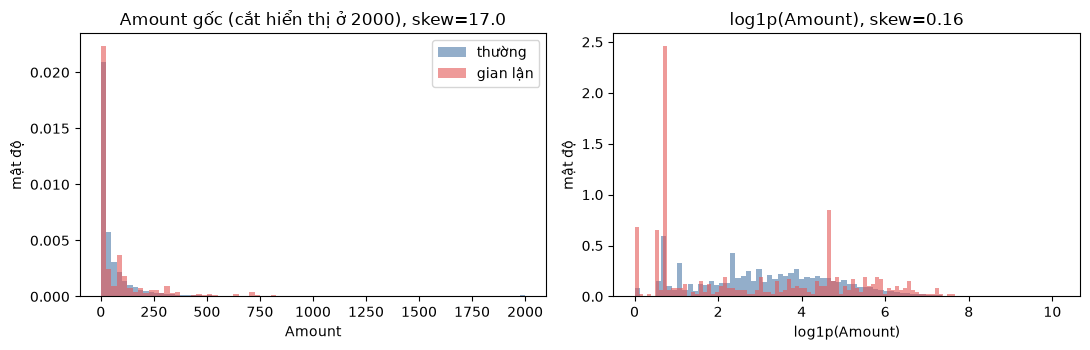

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for c, col, name in [(0, "#4C78A8", "thường"), (1, "#E45756", "gian lận")]:
    s = raw.loc[raw.Class == c, "Amount"]
    ax[0].hist(s.clip(upper=2000), bins=80, alpha=.6, color=col, density=True, label=name)
    ax[1].hist(np.log1p(s), bins=80, alpha=.6, color=col, density=True, label=name)
ax[0].set_title(f"Amount gốc (cắt hiển thị ở 2000), skew={C['amount_skew_raw']:.1f}"); ax[0].set_xlabel("Amount"); ax[0].legend()
ax[1].set_title(f"log1p(Amount), skew={C['amount_skew_log1p']:.2f}"); ax[1].set_xlabel("log1p(Amount)")
for a in ax: a.set_ylabel("mật độ")
plt.tight_layout(); plt.savefig(FIG / "fig04_amount_transform.png", dpi=150); plt.show()

**Quyết định D-03/D-04:** không xoá dòng nào vì Amount lớn hay bằng 0 (xoá dòng `|z|>10` mất 47% fraud, xoá Amount=0 mất 27 fraud, theo audit). Dùng `log1p` vì xác định được tại 0 và không cần fit (không rò rỉ). Sau đó StandardScaler **fit trên train** trong pipeline. Thêm cờ `is_zero_amount` để kho dữ liệu/dashboard lọc được nhóm này, nhưng **không** đưa vào bộ đặc trưng mặc định.

### 2.4 `Time` (DQ-05)
`Time` là giây kể từ giao dịch đầu tiên, không phải timestamp. Cột dẫn xuất được tạo:
- `rel_day = time_sec // 86400` (0/1): ranh giới 86 400 s là **giả định**, dùng để định nghĩa "ngày" cho ngân sách 100/ngày.
- `rel_hour = time_sec // 3600` (0–47): giờ kể từ giao dịch đầu.
- `hour_of_cycle = rel_hour % 24` và `hour_cycle_sin/cos`: vị trí trong chu kỳ 24h **tương đối** (lệch giờ đồng hồ thật một khoảng không biết). **Không được gọi là "giờ trong ngày"/"ban đêm".**

Brief ghi "biến đổi Time thành giờ trong ngày". Dữ liệu không cho phép làm đúng nghĩa đó, nên nhóm dùng giờ tương đối (mục I.3 trong tài liệu nhóm, chờ nhóm xác nhận).

## 3. Tạo bảng đã xử lý (bước B7–B10)

In [8]:
df = P.build_processed(raw)
print("shape:", df.shape)
print("cột:", list(df.columns))
df.head(3).T.head(20)

shape: (284807, 47)
cột: ['txn_id', 'time_sec', 'rel_day', 'rel_hour', 'hour_of_cycle', 'hour_cycle_sin', 'hour_cycle_cos', 'amount', 'amount_log1p', 'amount_band_id', 'amount_band', 'is_zero_amount', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'is_fraud', 'is_duplicate', 'dup_of_txn_id', 'in_model_set', 'split_temporal', 'split_random', 'cv_fold']


,0,1,2
txn_id,1,2,3
time_sec,0,0,1
rel_day,0,0,0
rel_hour,0,0,0
hour_of_cycle,0,0,0
hour_cycle_sin,0.0,0.0,0.000073
hour_cycle_cos,1.0,1.0,1.0
amount,149.62,2.69,378.66
amount_log1p,5.01476,1.305626,5.939276
amount_band_id,4,1,4


## 4. Giao thức chia tập (bước B6), đề xuất cho Huy & Mong xác nhận
- **`split_temporal` (CHÍNH):** test = toàn bộ `rel_day=1` (một "ngày" trọn vẹn), nên "top-100 của ngày test" khớp đúng câu hỏi nghiệp vụ. `rel_day=0` chia phân tầng 80/20 thành train/val (chọn tham số trên val). Mô phỏng thực tế: học từ quá khứ, chấm ngày kế tiếp (cũng là "thử thách nâng cao" của brief).
- **`split_random` (PHỤ):** phân tầng 60/20/20 + `cv_fold` (5-fold phân tầng trên train+val), dùng để báo **độ dao động** (rubric tiêu chí 7). Lưu ý: test ngẫu nhiên chỉ chứa ~20% giao dịch của cả hai ngày, nên "100/ngày" **không** áp nguyên được, phải quy đổi ngân sách theo tỷ lệ (≈ 100 × 2 ngày × 20% = 40 giao dịch) và ghi rõ.
- Bản sao (`is_duplicate=1`) không thuộc tập nào (`excluded_duplicate`, `cv_fold=-1`).

In [9]:
def split_table(col):
    t = df.groupby(col)[P.LABEL].agg(n="size", fraud="sum")
    t["fraud_rate_%"] = (t["fraud"] / t["n"] * 100).round(4)
    return t
st, sr = split_table("split_temporal"), split_table("split_random")
cv = df[df.cv_fold >= 0].groupby("cv_fold")[P.LABEL].agg(n="size", fraud="sum")
C["split_temporal"] = st.reset_index().to_dict("records"); C["split_random"] = sr.reset_index().to_dict("records")
C["cv_folds"] = cv.reset_index().to_dict("records")
display(st); display(sr); display(cv)

,n,fraud,fraud_rate_%
split_temporal,,,
excluded_duplicate,1081,19,1.7576
test,139490,201,0.1441
train,115388,218,0.1889
val,28848,54,0.1872


,n,fraud,fraud_rate_%
split_random,,,
excluded_duplicate,1081,19,1.7576
test,56746,95,0.1674
train,170235,284,0.1668
val,56745,94,0.1657


,n,fraud
cv_fold,,
0,45396,75
1,45396,75
2,45396,76
3,45396,76
4,45396,76


In [10]:
# Trần lý thuyết cho từng giao thức (bộ xếp hạng HOÀN HẢO)
te_fraud = int(st.loc["test", "fraud"])
C["temporal_test_ceiling_caught"] = min(P.REVIEW_BUDGET_PER_DAY, te_fraud)
C["temporal_test_ceiling_recall"] = C["temporal_test_ceiling_caught"] / te_fraud
print(f"Temporal test (rel_day=1): {int(st.loc['test','n']):,} giao dịch, {te_fraud} fraud → top-100 hoàn hảo bắt tối đa "
      f"{C['temporal_test_ceiling_caught']}/{te_fraud} = {C['temporal_test_ceiling_recall']*100:.2f}% (Precision@100 tối đa = 100%)")
m = df[df.in_model_set == 1]
per_day = m.groupby("rel_day")[P.LABEL].sum()
C["model_set_fraud_per_day"] = {int(k): int(v) for k, v in per_day.items()}
C["model_set_ceiling_recall_100_per_day"] = float(per_day.clip(upper=100).sum() / per_day.sum())
print(f"Tập mô hình (sau bỏ bản sao), fraud/ngày: {C['model_set_fraud_per_day']} → trần 100/ngày = {C['model_set_ceiling_recall_100_per_day']*100:.2f}%"
      f" (audit trên raw: {AUDIT['max_recall_perfect_ranker_100_per_day']*100:.2f}%)")

Temporal test (rel_day=1): 139,490 giao dịch, 201 fraud → top-100 hoàn hảo bắt tối đa 100/201 = 49.75% (Precision@100 tối đa = 100%)


Tập mô hình (sau bỏ bản sao), fraud/ngày: {0: 272, 1: 201} → trần 100/ngày = 42.28% (audit trên raw: 40.65%)


## 5. Pipeline có học từ dữ liệu & kiểm tra rò rỉ (bước B8, B9)
Minh hoạ cách Huy/Mong phải dùng: **fit trên train**, chỉ `transform` val/test. Bằng chứng: sau chuẩn hoá, trung bình `amount_log1p` trên train = 0 (đúng định nghĩa), còn trên val/test **khác 0**. Nếu cả ba đều đúng 0 thì đã fit nhầm trên toàn bộ.

In [11]:
Xtr, ytr, _ = P.get_split(df, "temporal", "train")
Xva, yva, _ = P.get_split(df, "temporal", "val")
Xte, yte, _ = P.get_split(df, "temporal", "test")
pre_t = P.make_preprocessor().fit(Xtr)            # CHỈ train
Ztr, Zva, Zte = (pre_t.transform(x) for x in (Xtr, Xva, Xte))
sc = pre_t.named_transformers_["scale"]
print("scaler học từ train: mean(amount_log1p) =", round(float(sc.mean_[0]), 6), "| scale =", round(float(sc.scale_[0]), 6))
lk = pd.DataFrame({p: {"mean": z["amount_log1p"].mean(), "std": z["amount_log1p"].std()} for p, z in [("train", Ztr), ("val", Zva), ("test", Zte)]}).T.round(4)
C["scaled_amount_stats_temporal"] = lk.reset_index().rename(columns={"index": "part"}).to_dict("records")
print("cột đầu ra pipeline:", list(Ztr.columns)[:3], "…", len(Ztr.columns), "cột")
lk

scaler học từ train: mean(amount_log1p) = 3.184651 | scale = 1.662026
cột đầu ra pipeline: ['amount_log1p', 'V1', 'V2'] … 29 cột


,mean,std
train,0.0000,1.0000
val,0.0017,1.0035
test,-0.0381,0.9928


In [12]:
# Các kiểm tra rò rỉ, mỗi dòng là một assert có thể kiểm tra lại
L = {}
L["label_not_in_FEATURES"] = P.LABEL not in P.FEATURES and "Class" not in P.FEATURES
L["label_not_in_X_columns"] = P.LABEL not in Xtr.columns
L["no_time_index_in_default_features"] = not set(P.FEATURES) & {"time_sec", "rel_day", "rel_hour"}
for col in ["split_temporal", "split_random"]:
    ids = {p: set(df.loc[df[col] == p, "txn_id"]) for p in ["train", "val", "test"]}
    L[f"{col}_parts_disjoint"] = not (ids["train"] & ids["val"] or ids["train"] & ids["test"] or ids["val"] & ids["test"])
    L[f"{col}_covers_model_set"] = sum(map(len, ids.values())) == int(df.in_model_set.sum())
    L[f"{col}_no_duplicate_rows_in_parts"] = bool((df.loc[df[col] != P.SPLIT_EXCLUDED, "is_duplicate"] == 0).all())
L["temporal_test_is_day1_only"] = set(df.loc[df.split_temporal == "test", "rel_day"]) == {1}
L["temporal_trainval_is_day0_only"] = set(df.loc[df.split_temporal.isin(["train", "val"]), "rel_day"]) == {0}
L["cv_only_on_random_trainval"] = set(df.loc[df.cv_fold >= 0, "split_random"]) == {"train", "val"}
L["scaler_fit_on_train_only"] = abs(lk.loc["train", "mean"]) < 1e-9 and abs(lk.loc["test", "mean"]) > 1e-6

# Bản sao raw y hệt giữa train và test: sau khi bỏ bản sao phải bằng 0 (Khang đo 456 trước khi xử lý)
h = pd.util.hash_pandas_object(raw, index=False).to_numpy()
for col in ["split_temporal", "split_random"]:
    tr_h = set(h[(df[col] == "train").to_numpy()]); te_mask = (df[col] == "test").to_numpy()
    C[f"{col}_test_rows_with_exact_copy_in_train"] = int(pd.Series(h[te_mask]).isin(tr_h).sum())
    L[f"{col}_no_exact_copy_train_test"] = C[f"{col}_test_rows_with_exact_copy_in_train"] == 0

# Trùng ĐẶC TRƯNG (khác Time) giữa train và test: ghi lại, không phải lỗi (xem D-11)
fh = pd.util.hash_pandas_object(df[P.FEATURES], index=False).to_numpy()
for col in ["split_temporal", "split_random"]:
    tr_f = set(fh[(df[col] == "train").to_numpy()]); te_mask = (df[col] == "test").to_numpy()
    C[f"{col}_test_rows_feature_equal_to_train"] = int(pd.Series(fh[te_mask]).isin(tr_f).sum())

C["leakage_checks"] = {k: bool(v) for k, v in L.items()}
print(pd.Series(C["leakage_checks"]).to_string())
print({k: v for k, v in C.items() if k.endswith("_in_train") or k.endswith("_to_train")})
assert all(L.values()), "Có kiểm tra rò rỉ không đạt"

label_not_in_FEATURES                        True
label_not_in_X_columns                       True
no_time_index_in_default_features            True
split_temporal_parts_disjoint                True
split_temporal_covers_model_set              True
split_temporal_no_duplicate_rows_in_parts    True
split_random_parts_disjoint                  True
split_random_covers_model_set                True
split_random_no_duplicate_rows_in_parts      True
temporal_test_is_day1_only                   True
temporal_trainval_is_day0_only               True
cv_only_on_random_trainval                   True
scaler_fit_on_train_only                     True
split_temporal_no_exact_copy_train_test      True
split_random_no_exact_copy_train_test        True
{'split_temporal_test_rows_with_exact_copy_in_train': 0, 'split_random_test_rows_with_exact_copy_in_train': 0, 'split_temporal_test_rows_feature_equal_to_train': 0, 'split_random_test_rows_feature_equal_to_train': 1908}


## 6. Kiểm tra sau xử lý (bước B11)

In [13]:
post = {
    "shape": list(df.shape),
    "n_null_cells": int(df.isna().sum().sum()),
    "txn_id_unique": bool(df["txn_id"].is_unique),
    "txn_id_range": [int(df.txn_id.min()), int(df.txn_id.max())],
    "label_counts_all_rows": {int(k): int(v) for k, v in df[P.LABEL].value_counts().sort_index().items()},
    "label_counts_model_set": {int(k): int(v) for k, v in df.loc[df.in_model_set == 1, P.LABEL].value_counts().sort_index().items()},
    "n_model_set": int(df.in_model_set.sum()), "n_duplicate_flagged": int(df.is_duplicate.sum()),
    "amount_sum_raw": round(float(raw.Amount.sum()), 2), "amount_sum_processed": round(float(df.amount.sum()), 2),
    "V_identical_to_raw": bool(np.array_equal(df[P.V_COLS].to_numpy(), raw[P.V_COLS].to_numpy())),
    "label_identical_to_raw": bool((df[P.LABEL].to_numpy() == raw["Class"].to_numpy()).all()),
    "time_identical_to_raw": bool((df["time_sec"].to_numpy() == raw["Time"].to_numpy()).all()),
    "rel_day_values": sorted(map(int, df.rel_day.unique())), "rel_hour_range": [int(df.rel_hour.min()), int(df.rel_hour.max())],
    "amount_band_counts": df.groupby(["amount_band_id", "amount_band"]).size().reset_index(name="n").to_dict("records"),
    "dtypes": {c: str(t) for c, t in df.dtypes.items()},
}
band_fraud = df.groupby("amount_band", sort=False)[P.LABEL].sum()
khang_band = {b["Amount"].replace("–", "-"): b["fraud"] for b in AUDIT["amount_bands"]}
post["amount_band_fraud_matches_audit"] = all(int(band_fraud[k]) == v for k, v in khang_band.items())
ok = (post["n_null_cells"] == 0 and post["txn_id_unique"] and post["label_counts_all_rows"] == {0: AUDIT["n_nonfraud"], 1: AUDIT["n_fraud"]}
      and post["amount_sum_raw"] == post["amount_sum_processed"] and post["V_identical_to_raw"] and post["label_identical_to_raw"]
      and post["time_identical_to_raw"] and post["amount_band_fraud_matches_audit"] and post["shape"][0] == AUDIT["n_rows"])
C["post_checks"] = post; C["post_checks_all_ok"] = bool(ok)
print(json.dumps({k: v for k, v in post.items() if k not in ("dtypes", "amount_band_counts")}, ensure_ascii=False, indent=1))
assert ok, "Kiểm tra sau xử lý không đạt"

{
 "shape": [
  284807,
  47
 ],
 "n_null_cells": 0,
 "txn_id_unique": true,
 "txn_id_range": [
  1,
  284807
 ],
 "label_counts_all_rows": {
  "0": 284315,
  "1": 492
 },
 "label_counts_model_set": {
  "0": 283253,
  "1": 473
 },
 "n_model_set": 283726,
 "n_duplicate_flagged": 1081,
 "amount_sum_raw": 25162590.01,
 "amount_sum_processed": 25162590.01,
 "V_identical_to_raw": true,
 "label_identical_to_raw": true,
 "time_identical_to_raw": true,
 "rel_day_values": [
  0,
  1
 ],
 "rel_hour_range": [
  0,
  47
 ],
 "amount_band_fraud_matches_audit": true
}


## 7. Ghi file đã xử lý + schema

In [14]:
df.to_csv(PROC_PATH, index=False, encoding="utf-8", lineterminator="\n")
C["processed_file"] = str(PROC_PATH.relative_to(ROOT)).replace("\\", "/")
C["processed_sha256"] = P.file_sha256(PROC_PATH); C["processed_size_bytes"] = PROC_PATH.stat().st_size
# đọc lại để chắc chắn round-trip không đổi giá trị
back = P.load_processed(PROC_PATH)
C["roundtrip_equal"] = bool(back.shape == df.shape and np.array_equal(back[P.V_COLS + ["amount", "amount_log1p"]].to_numpy(),
                                                                       df[P.V_COLS + ["amount", "amount_log1p"]].to_numpy())
                            and (back.split_temporal.to_numpy() == df.split_temporal.to_numpy()).all())
assert C["roundtrip_equal"]
print(C["processed_file"], f"{C['processed_size_bytes']/1e6:.1f} MB", C["processed_sha256"])

data/processed/transactions_processed.csv 180.5 MB e8bf7dcde41cb325482455a040154389dd57d7764fa44d72816dbcbe93628958


In [15]:
DESC = {
 "txn_id": ("int64", "Khoá giao dịch = số thứ tự dòng trong creditcard.csv (1-based)", "D-01", "Ổn định khi raw có sha256 đã audit"),
 "time_sec": ("int64", "Time gốc (giây kể từ giao dịch đầu tiên), ép int", "D-05", "KHÔNG phải timestamp"),
 "rel_day": ("int64", "time_sec // 86400 → 0/1", "D-05", "Ranh giới 86 400 s là giả định"),
 "rel_hour": ("int64", "time_sec // 3600 → 0..47", "D-05", "Giờ kể từ giao dịch đầu, không phải giờ đồng hồ"),
 "hour_of_cycle": ("int64", "rel_hour % 24 → 0..23", "D-05", "Chu kỳ 24h tương đối; KHÔNG gọi là giờ trong ngày"),
 "hour_cycle_sin": ("float64", "sin(2π·(time_sec mod 86400)/86400)", "D-07", "Chỉ dùng nếu thử biến thể FEATURES_WITH_CYCLE trên val"),
 "hour_cycle_cos": ("float64", "cos(2π·(time_sec mod 86400)/86400)", "D-07", "như trên"),
 "amount": ("float64", "Amount gốc, không sửa", "D-03/D-04", "Không rõ đơn vị tiền"),
 "amount_log1p": ("float64", "log(1 + amount); không cần fit", "D-04", "Chuẩn hoá thêm trong pipeline (fit trên train)"),
 "amount_band_id": ("int64", "0..6 theo ranh giới (−∞,0],(0,10],(10,50],(50,100],(100,500],(500,1000],(1000,∞)", "D-08", "Cùng ranh giới với audit của Khang"),
 "amount_band": ("string", "Nhãn dải: 0, 0-10, 10-50, 50-100, 100-500, 500-1000, >1000", "D-08", "Dùng cho Dim_AmountBand/dashboard"),
 "is_zero_amount": ("int64", "1 nếu amount = 0", "D-03", "Ý nghĩa Amount=0 không được nguồn giải thích"),
 "V1…V28": ("float64", "Thành phần PCA gốc, không sửa", "D-07", "Không gán ý nghĩa nghiệp vụ"),
 "is_fraud": ("int64", "Nhãn = Class gốc (1 gian lận, 0 còn lại)", "—", "CHỈ để đánh giá/học có giám sát; không bao giờ là feature"),
 "is_duplicate": ("int64", "1 nếu là bản sao thừa (trùng cả 31 cột với một dòng trước)", "D-02", "Bị loại khỏi tập mô hình"),
 "dup_of_txn_id": ("int64", "txn_id của bản được giữ trong nhóm trùng (dòng không trùng = chính nó)", "D-02", "Để kho dữ liệu truy vết"),
 "in_model_set": ("int64", "1 − is_duplicate", "D-02", "Lọc tập dùng cho mô hình"),
 "split_temporal": ("string", "train / val / test / excluded_duplicate (test = rel_day 1; train/val = rel_day 0 phân tầng 80/20)", "D-06", "Giao thức CHÍNH đề xuất"),
 "split_random": ("string", "train / val / test / excluded_duplicate (phân tầng 60/20/20)", "D-06", "Giao thức PHỤ"),
 "cv_fold": ("int64", "0..4 = fold phân tầng trên train+val của split_random; −1 = không thuộc", "D-06", "Báo độ dao động"),
}
lines = [f"# Data dictionary — dữ liệu đã xử lý (schema v{P.SCHEMA_VERSION})",
         f"File: `{C['processed_file']}` · {post['shape'][0]:,} dòng × {post['shape'][1]} cột · sha256 `{C['processed_sha256']}`  ",
         f"Sinh tự động bởi `notebooks/02_preprocessing.ipynb` ngày {C['run_date']}. Logic: `src/preprocessing.py`. Grain: **1 dòng = 1 giao dịch** (giống raw).", "",
         "| Cột | Kiểu | Định nghĩa | Quyết định | Giới hạn / lưu ý |", "|---|---|---|---|---|"]
lines += [f"| `{k}` | {t} | {d} | {r} | {n} |" for k, (t, d, r, n) in DESC.items()]
lines += ["", f"**Bộ đặc trưng mặc định (`P.FEATURES`, {len(P.FEATURES)} cột):** `V1…V28`, `amount_log1p`. Nhãn: `is_fraud`.",
          "**Biến đổi có học (chỉ fit trên train/fold):** `P.make_preprocessor()` = StandardScaler cho `amount_log1p`, V* passthrough (tuỳ chọn `scale_v=True`)."]
(OUT / "processed_data_dictionary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
schema = {"schema_version": P.SCHEMA_VERSION, "file": C["processed_file"], "sha256": C["processed_sha256"], "grain": "1 row = 1 transaction",
          "columns": [{"name": c, "dtype": post["dtypes"][c]} for c in df.columns], "primary_key": "txn_id", "label": P.LABEL,
          "features_default": P.FEATURES, "features_with_cycle": P.FEATURES_WITH_CYCLE, "random_state": P.RANDOM_STATE,
          "split_columns": ["split_temporal", "split_random", "cv_fold"], "excluded_value": P.SPLIT_EXCLUDED}
(OUT / "processed_schema.json").write_text(json.dumps(schema, ensure_ascii=False, indent=2), encoding="utf-8")
print("đã ghi processed_data_dictionary.md, processed_schema.json")

đã ghi processed_data_dictionary.md, processed_schema.json


## 8. Nhật ký quyết định (bước B12), sinh từ số đo ở trên
Trạng thái "Đề xuất – chờ duyệt" nghĩa là Cường đã chọn và có bằng chứng, nhưng thành viên liên quan cần xác nhận (theo cổng "hợp đồng dữ liệu").

In [16]:
D = []
def dec(i, issue, evidence, choice, alts, reason, impact, approver, status="Đề xuất – chờ duyệt"):
    D.append(dict(ID=i, Van_de=issue, Bang_chung=evidence, Lua_chon=choice, Phuong_an_thay_the=alts, Ly_do=reason,
                  Anh_huong_toi_con_so=impact, Nguoi_duyet=approver, Trang_thai=status, Ngay_phien_ban=f"{C['run_date']} / schema v{P.SCHEMA_VERSION}"))
tst = {r["split_temporal"]: r for r in C["split_temporal"]}; srn = {r["split_random"]: r for r in C["split_random"]}

dec("D-01", "Khoá giao dịch", "Raw không có cột ID; Time có 160 215 dòng trùng giá trị (audit) nên không làm khoá được.",
    "txn_id = số thứ tự dòng trong raw (1..284 807).", "Hash nội dung dòng (không duy nhất vì có bản sao); UUID ngẫu nhiên (không tái lập).",
    "Tái lập được vì raw cố định theo sha256; duy nhất; Quỳnh dùng làm khoá tự nhiên của Fact_Transaction.",
    "Mọi join giữa notebook, SQL và dashboard (bảng score của Huy/Mong dùng txn_id).", "Quỳnh (C)", "Đã áp dụng")
dec("D-02", "Bản sao hoàn toàn (DQ-01)",
    f"{C['dup_extra_rows']:,} bản sao thừa trong {C['dup_groups']} nhóm (nhóm lớn nhất {C['dup_max_group_size']} dòng), trùng cả Time đến từng giây; {C['dup_extra_fraud']} fraud. Audit: 456 dòng test có bản sao trong train khi split ngẫu nhiên.",
    "Giữ bản đầu tiên cho mô hình; gắn cờ is_duplicate=1 cho bản sau (in_model_set=0); KHÔNG xoá khỏi file đã xử lý.",
    "(a) Giữ tất cả và báo số đo kèm/không kèm bản sao; (b) xoá hẳn khỏi file.",
    "Bản sao y hệt cả thời điểm là bản ghi lặp, không phải giao dịch mới; để trong cả train và test làm LOF/k-NN 'thấy' điểm test (rò rỉ). Giữ trong file để kho dữ liệu đối soát đủ 284 807 dòng với raw.",
    f"Tập mô hình: {post['n_model_set']:,} dòng, {C['fraud_after_dedup']} fraud (mất {C['dup_extra_fraud']} nhãn fraud = {C['dup_extra_fraud']/AUDIT['n_fraud']*100:.1f}%). Mọi mẫu số Recall/PR-AUC dùng tập này. OLAP phải ghi rõ đếm có/không is_duplicate.",
    "Cường + Khang; báo Quỳnh, Huy, Mong")
dec("D-03", "Amount = 0 (DQ-02)", f"{AUDIT['amount_zero_rows']:,} dòng, {AUDIT['amount_zero_fraud']} fraud (tỷ lệ fraud 1,48% so với 0,173%).",
    "Giữ nguyên; thêm cờ is_zero_amount (không nằm trong FEATURES mặc định).", "Xoá; thay bằng NaN rồi impute.",
    "Không có căn cứ coi 0 là lỗi; xoá mất 27 fraud và nhóm có tỷ lệ fraud ~8,6 lần trung bình. log1p(0)=0 nên không cần xử lý đặc biệt.",
    "Số dòng và fraud giữ nguyên; dashboard lọc được nhóm Amount=0.", "Cường", "Đã áp dụng")
dec("D-04", "Amount lệch phải nặng (DQ-04)",
    f"skew {C['amount_skew_raw']:.2f} → {C['amount_skew_log1p']:.2f} sau log1p; kurtosis {C['amount_kurt_raw']:.0f} → {C['amount_kurt_log1p']:.2f}. 31 904 dòng vượt hàng rào IQR, có 91 fraud (audit).",
    "amount_log1p = log1p(Amount) (stateless, tính sẵn) → StandardScaler trong pipeline, fit trên train/fold. Không xoá outlier.",
    "RobustScaler trên Amount gốc; sqrt; QuantileTransformer (có fit → phải trong pipeline).",
    "log1p giảm lệch mạnh nhất trong các ứng viên ở §2.3, xác định tại 0, không học từ dữ liệu nên không rò rỉ. Xoá outlier = xoá chính các ca cần phát hiện.",
    "Khoảng cách trong LOF và hệ số trong mô hình phân lớp; không đổi số dòng.", "Cường; Huy xác nhận cho LOF")
dec("D-05", "Time là giây tương đối (DQ-05)", f"Time 0–172 792 s, 0 giá trị không nguyên; không có ngày/giờ thật.",
    "time_sec (int); rel_day = //86400 (0/1); rel_hour = //3600 (0–47); hour_of_cycle = rel_hour % 24 (+ sin/cos).",
    "Gán ngày/giờ lịch giả (bịa); bỏ hẳn Time.",
    "Brief đề xuất 'giờ trong ngày' nhưng dữ liệu không có mốc giờ thật; giờ/ngày TƯƠNG ĐỐI là phần dữ liệu cho phép. Ranh giới 86 400 s cần để định nghĩa '100 giao dịch/ngày'.",
    "Định nghĩa 'ngày' cho Precision@100/ngày và trần recall; Dim_Date/Dim_Hour của Quỳnh phải đặt tên 'tương đối'.",
    "Cả nhóm (mục I.3); Quỳnh")
dec("D-06", "Giao thức chia tập",
    f"Temporal: train {tst['train']['n']:,}/{tst['train']['fraud']} fraud, val {tst['val']['n']:,}/{tst['val']['fraud']}, test (ngày 1) {tst['test']['n']:,}/{tst['test']['fraud']}. Random 60/20/20: train {srn['train']['n']:,}/{srn['train']['fraud']}, val {srn['val']['n']:,}/{srn['val']['fraud']}, test {srn['test']['n']:,}/{srn['test']['fraud']}. Sau bỏ bản sao: 0 dòng test có bản sao y hệt trong train ở cả hai giao thức.",
    "CHÍNH: split_temporal (train/val = ngày 0 phân tầng 80/20, test = ngày 1). PHỤ: split_random phân tầng 60/20/20 + cv_fold 5-fold trên train+val. random_state=42. Chọn tham số trên val/CV, KHÔNG trên test.",
    "Chỉ split ngẫu nhiên 70/30 (như audit); k-fold trên toàn bộ.",
    f"Test = một ngày trọn vẹn làm 'top-100/ngày' đúng nghĩa nghiệp vụ và mô phỏng học quá khứ, chấm ngày sau. Random + CV để báo độ dao động. Trần top-100 hoàn hảo trên test temporal = {C['temporal_test_ceiling_caught']}/{tst['test']['fraud']} = {C['temporal_test_ceiling_recall']*100:.2f}%.",
    "Precision@100, Recall@100, PR-AUC của Huy/Mong; với split_random phải quy đổi ngân sách (test chỉ ~20% giao dịch).",
    "Huy (D) + Mong (E) xác nhận (mục I.5, I.6)")
dec("D-07", "Bộ đặc trưng & chuẩn hoá (DQ-06)",
    "std V1=1,96 … V28=0,33; Time std ≈ 47 488; Time tăng đơn điệu theo thứ tự file (audit time_sorted=True).",
    "FEATURES = V1…V28 + amount_log1p (29 cột). Không đưa time_sec/rel_day/rel_hour. V* passthrough; chỉ amount_log1p chuẩn hoá. Biến thể FEATURES_WITH_CYCLE (thêm sin/cos) và scale_v=True để thử trên val.",
    "Đưa Time thô vào; chuẩn hoá tất cả 29 cột.",
    "Time thô là chỉ số thời gian: với split temporal, giá trị test nằm ngoài miền train (ngoại suy); với split ngẫu nhiên, mô hình học 'thời điểm' thay vì hành vi. V* đã là PCA (trung bình ≈ 0), độ lớn phương sai mang thông tin thứ tự thành phần, nên giữ nguyên hình học; Isolation Forest không bị ảnh hưởng bởi co giãn tuyến tính.",
    "Điểm bất thường của LOF (dựa khoảng cách) và mô hình phân lớp.", "Huy (D), Mong (E)")
dec("D-08", "Dải tiền (Dim_AmountBand)", "Audit của Khang dùng ranh giới 0 | 0–10 | 10–50 | 50–100 | 100–500 | 500–1000 | >1000.",
    "Dùng đúng ranh giới đó (amount_band_id 0–6, nhãn ASCII).", "Dải theo phân vị (quantile).",
    f"Số liệu notebook, SQL và dashboard khớp với audit (kiểm tra: fraud theo dải khớp = {post['amount_band_fraud_matches_audit']}).",
    "Biểu đồ 'gian lận theo mức tiền' trên dashboard.", "Quỳnh (C), Mong (E)")
dec("D-09", "Giá trị thiếu", f"Tổng ô thiếu = {AUDIT['n_missing_total']} (audit, tính lại khớp).", "Không impute.", "SimpleImputer dự phòng trong pipeline.",
    "Không có giá trị thiếu; thêm imputer chỉ làm phức tạp.", "Không.", "Cường", "Đã áp dụng")
dec("D-10", "Mất cân bằng lớp (DQ-03)", f"{C['fraud_after_dedup']} fraud / {post['n_model_set']:,} dòng trong tập mô hình.",
    "Không resample trong tiền xử lý; chia phân tầng. Nếu Mong dùng class_weight/oversampling thì CHỈ áp trên train (trong pipeline/fold).",
    "SMOTE/undersample trước khi chia (rò rỉ).", "Resample trước khi chia làm bản sao/điểm tổng hợp lọt sang test.",
    "Precision/Recall của mô hình phân lớp.", "Mong (E)")
dec("D-11", "Trùng đặc trưng nhưng khác Time (phát hiện mới)",
    f"{C['feature_dup_rows']:,} dòng trong {C['feature_dup_groups']:,} nhóm giống hệt nhau trên V1…V28+Amount nhưng khác Time (nhóm lớn nhất {C['feature_dup_max_group']}); {C['feature_dup_fraud']} fraud. Test temporal có {C['split_temporal_test_rows_feature_equal_to_train']:,} dòng trùng đặc trưng với train; test random có {C['split_random_test_rows_feature_equal_to_train']:,}.",
    "Giữ nguyên (không phải bản sao vì khác thời điểm). Báo Huy chọn n_neighbors của LOF > cỡ nhóm lớn nhất hoặc ghi ảnh hưởng.",
    "Gộp thành một dòng; loại khỏi test.",
    "Không có căn cứ coi là bản ghi lặp; đều là lớp thường nên không làm đẹp giả số đo fraud, nhưng ảnh hưởng mật độ cục bộ của LOF.",
    "Điểm LOF của các nhóm này; không đổi số fraud.", "Huy (D)")

dlog = pd.DataFrame(D); dlog.to_csv(OUT / "decision_log.csv", index=False, encoding="utf-8-sig")
C["n_decisions"] = len(dlog)
dlog[["ID", "Van_de", "Lua_chon", "Trang_thai"]]

,ID,Van_de,Lua_chon,Trang_thai
0,D-01,Khoá giao dịch,txn_id = số thứ tự dòng trong raw (1..284 807).,Đã áp dụng
1,D-02,Bản sao hoàn toàn (DQ-01),Giữ bản đầu tiên cho mô hình; gắn cờ is_duplic...,Đề xuất – chờ duyệt
2,D-03,Amount = 0 (DQ-02),Giữ nguyên; thêm cờ is_zero_amount (không nằm ...,Đã áp dụng
3,D-04,Amount lệch phải nặng (DQ-04),"amount_log1p = log1p(Amount) (stateless, tính ...",Đề xuất – chờ duyệt
4,D-05,Time là giây tương đối (DQ-05),time_sec (int); rel_day = //86400 (0/1); rel_h...,Đề xuất – chờ duyệt
5,D-06,Giao thức chia tập,CHÍNH: split_temporal (train/val = ngày 0 phân...,Đề xuất – chờ duyệt
6,D-07,Bộ đặc trưng & chuẩn hoá (DQ-06),FEATURES = V1…V28 + amount_log1p (29 cột). Khô...,Đề xuất – chờ duyệt
7,D-08,Dải tiền (Dim_AmountBand),"Dùng đúng ranh giới đó (amount_band_id 0–6, nh...",Đề xuất – chờ duyệt
8,D-09,Giá trị thiếu,Không impute.,Đã áp dụng
9,D-10,Mất cân bằng lớp (DQ-03),Không resample trong tiền xử lý; chia phân tần...,Đề xuất – chờ duyệt


## 9. Kiểm tra cuối: raw không đổi & ghi số đo

In [17]:
C["raw_sha256_after"] = P.file_sha256(RAW_PATH)
assert C["raw_sha256_after"] == P.EXPECTED_SHA256, "File raw đã bị thay đổi!"
(OUT / "preprocessing_checks.json").write_text(json.dumps(C, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("OK — checksum raw không đổi:", C["raw_sha256_after"])
print("leakage checks đạt:", all(C["leakage_checks"].values()), "| post checks đạt:", C["post_checks_all_ok"])

OK — checksum raw không đổi: 76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89
leakage checks đạt: True | post checks đạt: True
